In [1]:
from pathlib import Path
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

plt.rcParams["figure.dpi"] = 72   # keeps the notebook file small

%load_ext autoreload
%autoreload 2

# **Settings**

In [9]:
BOARD_VIDEO_DIR = Path("../data/videos")
DART_VIDEO_DIR = Path("../data/dart_videos")
FIGURE_DIR = Path("../reports/figures")

from src.config import *

SAVE_FIGURE = True

board_videos = sorted(BOARD_VIDEO_DIR.glob("*.mp4"))
dart_videos = sorted(DART_VIDEO_DIR.glob("*.mp4"))

# **Get Scenario Frames From Board Videos**

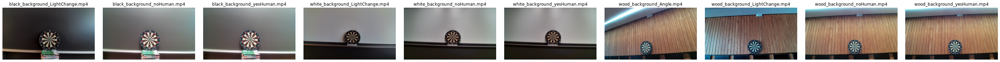

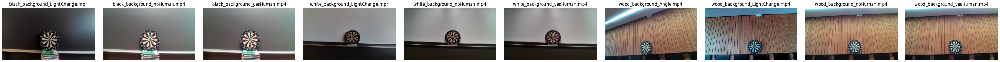

In [10]:
from src.calibration import median_frame
from src.visualization import show
frames = {}

for video in board_videos:
    median, first_frame = median_frame(BOARD_VIDEO_DIR / video.name)

    frames[video.name] = {
        "median": median,
        "first_frame": first_frame
    }

#### Display Images
show(
    images=[data["median"] for data in frames.values()],
    titles=list(frames.keys()),
    size=4
)

show(
    images=[data["first_frame"] for data in frames.values()],
    titles=list(frames.keys()),
    size=4
)

## **Single Scenarios**
- Artificial Light
- Natural Light
- 3 Different Backgrounds (Black, White, Wood)
- On an angle

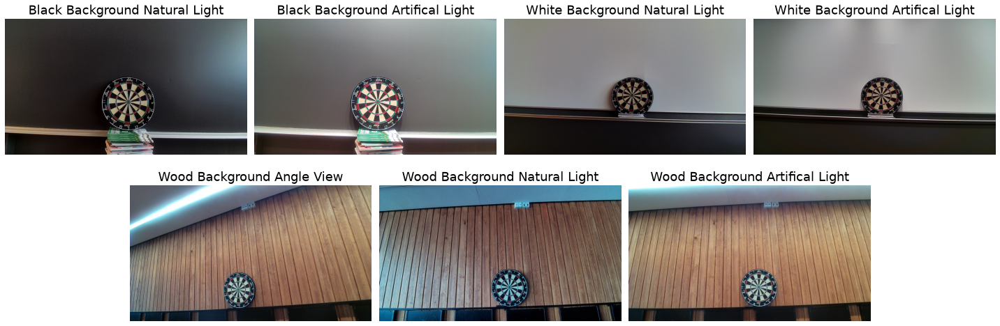

In [11]:

custom_titles = {
    "black_background_noHuman.mp4": "Black Background Artifical Light",
    "black_background_LightChange.mp4" : "Black Background Natural Light",
    "white_background_LightChange.mp4" : "White Background Natural Light",
    "white_background_noHuman.mp4" : "White Background Artifical Light",
    "wood_background_Angle.mp4" : "Wood Background Angle View",
    "wood_background_LightChange.mp4" : "Wood Background Natural Light",
    "wood_background_noHuman.mp4" : "Wood Background Artifical Light"
}

filtered_frames = {
    name: data["first_frame"]
    for name, data in frames.items()
    if "_yesHuman" not in name
}

fig = plt.figure(figsize=(20, 7))
gs = fig.add_gridspec(2, 8)

for i, (name, image) in enumerate(list(filtered_frames.items())[:7]):

    if i < 4:
        ax = fig.add_subplot(gs[0, i * 2:i * 2 + 2])
    else:
        start = 1 + (i - 4) * 2
        ax = fig.add_subplot(gs[1, start:start + 2])

    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

    title = custom_titles.get(name, Path(name).stem)
    ax.set_title(title, fontsize=18)

    ax.axis("off")
plt.tight_layout()

if SAVE_FIGURE:
    save_path = Path(FIGURE_DIR) / "Implementation" / "Scenario_images.pdf"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    plt.savefig(save_path, dpi=500, bbox_inches="tight")
plt.show()


# **Bullseye**

## **Chapter Images**

In [12]:
# Read Stock image
original = cv2.cvtColor(cv2.imread("..\\data\\dart_boards\\origin.png"), cv2.COLOR_BGR2RGB)  

### **Preprocessing the Original Image**

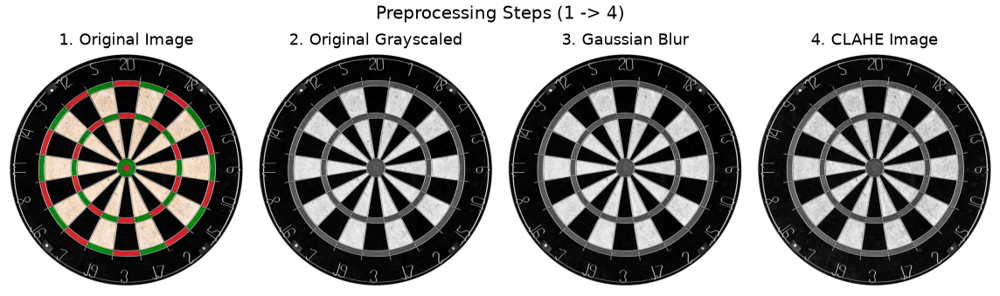

In [13]:
gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)           # Grayscale Image
gray_gaus = cv2.GaussianBlur(gray, (0, 0), 1)               # Gaussian Blur Image
clahe = cv2.createCLAHE(clipLimit=1, tileGridSize=(5,5))    # Create CLAHE
gray_clahe = clahe.apply(gray)                              # Apply CLAHE

# Plot each step
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

images = [
    original, gray, gray_gaus, gray_clahe
]

titles = [
    "1. Original Image",
    "2. Original Grayscaled",
    "3. Gaussian Blur",
    "4. CLAHE Image"
]

# Plot Images
for i, ax in enumerate(axes):
    if i > 1:
        ax.imshow(images[i], cmap="gray")
    else:
        ax.imshow(images[i], cmap="gray")
    ax.set_title(titles[i], fontsize = 18)
    ax.axis("off")
plt.suptitle("Preprocessing Steps (1 -> 4)", fontsize = 20)
plt.tight_layout()

if SAVE_FIGURE:
    save_path = Path(FIGURE_DIR) / "Implementation" / "Bullseye" / "Bullseye_preprocessing.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    plt.savefig(save_path, dpi=500, bbox_inches="tight")
plt.show()

### **Detecting Edges**

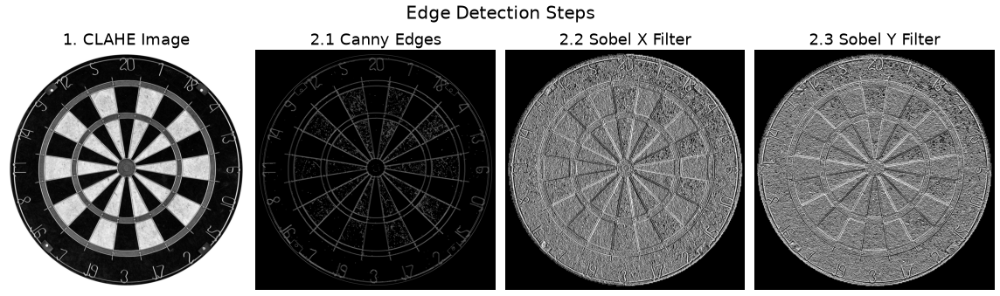

In [14]:

edges = cv2.Canny(gray_clahe, 200, 250)
gx = cv2.Sobel(gray_clahe, cv2.CV_32F, 1, 0)
gy = cv2.Sobel(gray_clahe, cv2.CV_32F, 0, 1)
ys, xs = np.nonzero(edges)
magnitude = np.hypot(gx[ys, xs], gy[ys, xs]) + 1e-6

# Plot each step
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

images = [
    gray_clahe, edges, gx, gy
]

titles = [
    "1. CLAHE Image",
    "2.1 Canny Edges",
    "2.2 Sobel X Filter",
    "2.3 Sobel Y Filter"
]

# Plot Images
for i, ax in enumerate(axes):
    if i > 1:
        ax.imshow(images[i] > 0, cmap="gray")
    else:
        ax.imshow(images[i], cmap="gray")
    ax.set_title(titles[i], fontsize = 18)
    ax.axis("off")
plt.suptitle("Edge Detection Steps", fontsize = 20)
plt.tight_layout()

if SAVE_FIGURE:
    save_path = Path(FIGURE_DIR) / "Implementation" / "Bullseye" / "Bullseye_edges.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    plt.savefig(save_path, dpi=500, bbox_inches="tight")
plt.show()

### **Voting**

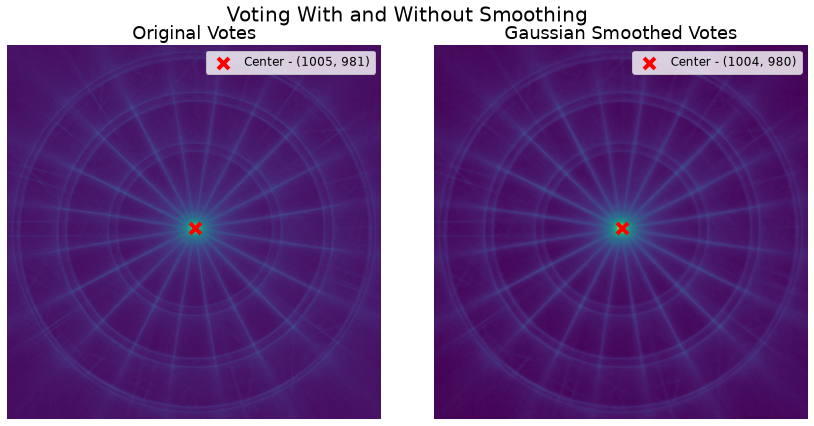

In [15]:
dx = -gy[ys, xs] / magnitude
dy = gx[ys, xs] / magnitude

votes = np.zeros(gray_clahe.shape, np.float32)
line_length = int(np.hypot(*gray_clahe.shape))

for t in range(-line_length, line_length + 1):
    px = np.round(xs + t * dx).astype(int)
    py = np.round(ys + t * dy).astype(int)
    inside = (px >= 0) & (px < gray_clahe.shape[1]) & (py >= 0) & (py < gray_clahe.shape[0])
    np.add.at(votes, (py[inside], px[inside]), 1)

votes_gaus = cv2.GaussianBlur(votes, (0, 0), 3)
y, x = np.unravel_index(np.argmax(votes), votes.shape)
y_gaus, x_gaus = np.unravel_index(np.argmax(votes_gaus), votes_gaus.shape)

peak = (int(x), int(y))
peak_gaus = (int(x_gaus), int(y_gaus))


# Plot both
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(votes)
axes[0].scatter(x, y, c="red", marker="x", s=120, linewidths=4, label = f"Center - {peak}")
axes[0].set_title(f"Original Votes", fontsize=18 )
axes[0].axis("off")
axes[0].legend(fontsize=12)

axes[1].imshow(votes_gaus)
axes[1].scatter(x_gaus, y_gaus, c="red", marker="x", s=120, linewidths=4 , label = f"Center - {peak_gaus}")
axes[1].set_title(f"Gaussian Smoothed Votes", fontsize=18)
axes[1].axis("off")
axes[1].legend(fontsize=12)

plt.suptitle("Voting With and Without Smoothing", fontsize = 20)
plt.tight_layout()

if SAVE_FIGURE:
    save_path = Path(FIGURE_DIR) / "Implementation" / "Bullseye" / "Bullseye_voting.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    plt.savefig(save_path, dpi=500, bbox_inches="tight")
plt.show()

## **Testing CLAHE and Gaussian Blurrint**

In [ ]:
from concurrent.futures import ThreadPoolExecutor
from itertools import product
from tqdm import tqdm
from src.calibration import find_centre


lims = [0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5]
grids = [(4,4),
         (5,5),(6,6), (7,7), (8,8), (9,9), (10,10)]

def evaluate_params(args):
    title, frame, lim, grid = args

    centre, edges, votes = find_centre(
        frame,
        clahe_lim=lim,
        clahe_grid=grid
    )

    return {
        "video_title": title,
        "clip_limit": lim,
        "grid": grid,
        "centre": centre,
        "max_votes": float(votes.max())
    }


tasks = [
    (title, data["first_frame"], lim, grid)
    for title, data in frames.items()
    for lim, grid in product(lims, grids)
]

results = []
# Uncomment to run
# with ThreadPoolExecutor(max_workers=7) as executor:
#     for result in tqdm(executor.map(evaluate_params, tasks),
#                        total=len(tasks)):
#         results.append(result)

100%|██████████| 700/700 [18:21<00:00,  1.57s/it]


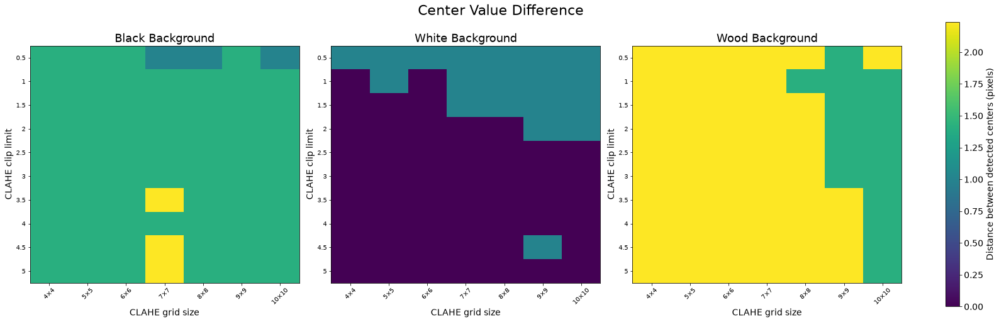

In [11]:
import numpy as np
import matplotlib.pyplot as plt

backgrounds = ["black", "white", "wood"]

fig, axes = plt.subplots(
    1, 3, figsize=(22, 7),
    constrained_layout=True
)

heatmaps = []

for background in backgrounds:

    normal = {
        (r["clip_limit"], tuple(r["grid"])): r["centre"]
        for r in results
        if r["video_title"].startswith(background + "_")
        and "noHuman" in r["video_title"]
    }

    light = {
        (r["clip_limit"], tuple(r["grid"])): r["centre"]
        for r in results
        if r["video_title"].startswith(background + "_")
        and "LightChange" in r["video_title"]
    }

    distances = np.full((len(lims), len(grids)), np.nan)
    annotations = {}

    for i, lim in enumerate(lims):
        for j, grid in enumerate(grids):

            key = (lim, grid)

            if key not in normal or key not in light:
                continue

            n = np.array(normal[key], dtype=float)
            l = np.array(light[key], dtype=float)

            distances[i, j] = np.linalg.norm(n - l)
            annotations[(i, j)] = (n, l)

    heatmaps.append((distances, annotations))

# Shared color scale
valid = [
    h[np.isfinite(h)]
    for h, _ in heatmaps
    if np.any(np.isfinite(h))
]

vmax = max(np.concatenate(valid).max(), 1) if valid else 1

for ax, background, (heatmap, annotations) in zip(
    axes, backgrounds, heatmaps
):

    im = ax.imshow(
        heatmap,
        cmap="viridis",
        vmin=0,
        vmax=vmax,
        aspect="auto"
    )

    ax.set_title(f"{background.capitalize()} Background", fontsize = 18)

    ax.set_xticks(range(len(grids)))
    ax.set_xticklabels(
        [f"{g[0]}×{g[1]}" for g in grids],
        rotation=45
    )

    ax.set_yticks(range(len(lims)))
    ax.set_yticklabels(lims)

    ax.set_xlabel("CLAHE grid size", fontsize = 14)
    ax.set_ylabel("CLAHE clip limit", fontsize = 14)

cbar = fig.colorbar(
    im,
    ax=axes,
    label="Distance between detected centers (pixels)",
    shrink=1.2
)
cbar.ax.tick_params(labelsize=14)  # Tick font size
cbar.set_label("Distance between detected centers (pixels)", fontsize=14)
fig.suptitle("Center Value Difference", fontsize = 22)

# save_path = Path(FIGURE_DIR) / "Implementation" / "Bullseye" / "Bullseye_center_noGauss.pdf"
save_path = Path(FIGURE_DIR) / "Implementation" / "Bullseye" / "Bullseye_center_withGauss.pdf"
save_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(save_path, dpi=500, bbox_inches="tight")
plt.show()

# **Board Inner & Outer Ellipse**

## **Polar Remapping**

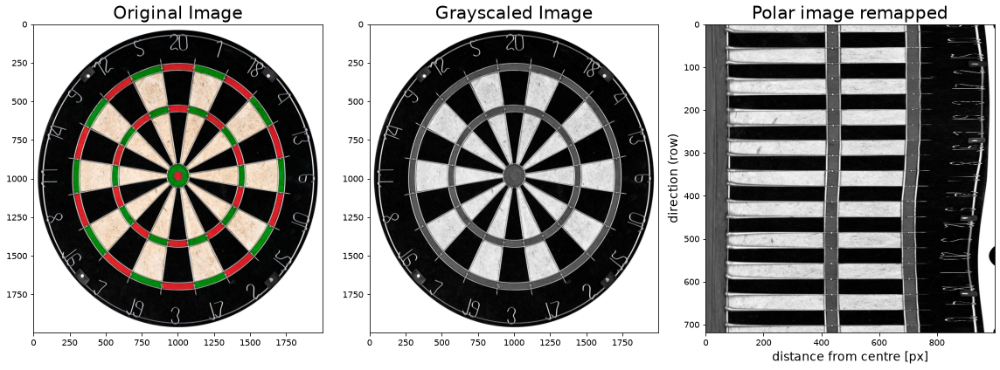

In [16]:
from src.calibration import find_centre
from src.geometry import polar_image

original = cv2.imread("..\\data\\dart_boards\\origin.png")
centre, edges, votes = find_centre(original)

gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
polar = polar_image(gray, centre, gray.shape[0] // 2)

fig, axs = plt.subplots(1, 3, figsize=(16, 6))

axs[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB), aspect="auto")
axs[0].set_title("Original Image", fontsize = 20)
axs[1].imshow(gray, cmap="gray", aspect="auto")
axs[1].set_title("Grayscaled Image", fontsize = 20)
axs[2].imshow(polar, cmap="gray", aspect="auto")
axs[2].set_title("Polar image remapped",fontsize = 20)
axs[2].set_ylabel("direction (row)",fontsize = 14)
axs[2].set_xlabel("distance from centre [px]",fontsize = 14)
plt.tight_layout()

if SAVE_FIGURE:
    save_path = Path(FIGURE_DIR) / "Implementation" / "Board Isolating" / "Polar_Remapping.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    fig.savefig(save_path, dpi=500, bbox_inches="tight")

plt.show()

## **Top Hat filtering & Dark ring detection**

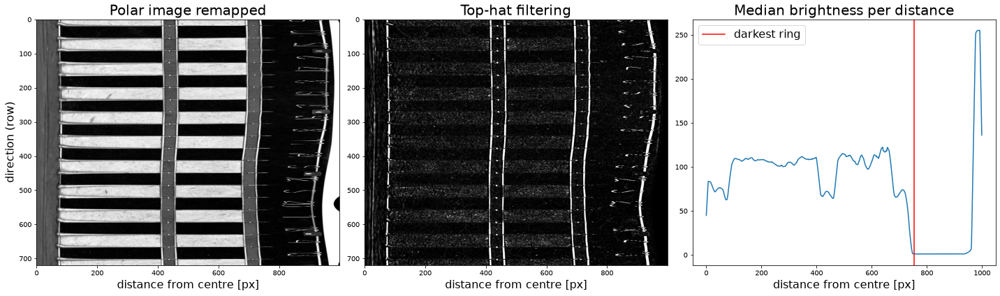

In [17]:
from src.calibration import find_centre, thin_bright_lines, darkest_ring, find_wire_points
from src.geometry import polar_image

original = cv2.imread("..\\data\\dart_boards\\origin.png")
centre, edges, votes = find_centre(original)

gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
polar = polar_image(gray, centre, gray.shape[0] // 2)

top_hat = thin_bright_lines(polar)
r_dark, profile = darkest_ring(polar)
wire_points = find_wire_points(top_hat, centre, r_dark)

fig, axs = plt.subplots(1, 3, figsize=(20, 6))

axs[0].imshow(polar, cmap="gray", aspect="auto")
axs[0].set_title("Polar image remapped", fontsize = 20)
axs[0].set_xlabel("distance from centre [px]", fontsize = 16)
axs[0].set_ylabel("direction (row)", fontsize = 16)

axs[1].imshow(np.clip(top_hat, 0, 60), cmap="gray", aspect="auto")
axs[1].set_title("Top-hat filtering", fontsize = 20)
axs[1].set_xlabel("distance from centre [px]", fontsize = 16)

axs[2].plot(profile)
axs[2].axvline(r_dark, color="r", label="darkest ring")
axs[2].set_title("Median brightness per distance", fontsize = 20)
axs[2].set_xlabel("distance from centre [px]", fontsize = 16)
axs[2].legend(fontsize = 16)
plt.tight_layout()

if SAVE_FIGURE:
    save_path = Path(FIGURE_DIR) / "Implementation" / "Board Isolating" / "Dark_Ring_Detection.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    fig.savefig(save_path, dpi=500, bbox_inches="tight")

plt.show()

## **Outer Ellipse**

395 of 720 directions agree with the ellipse
Outer ellipse: centre [1003.2 1004.2] axes [1865.  1877.3] angle 76.0


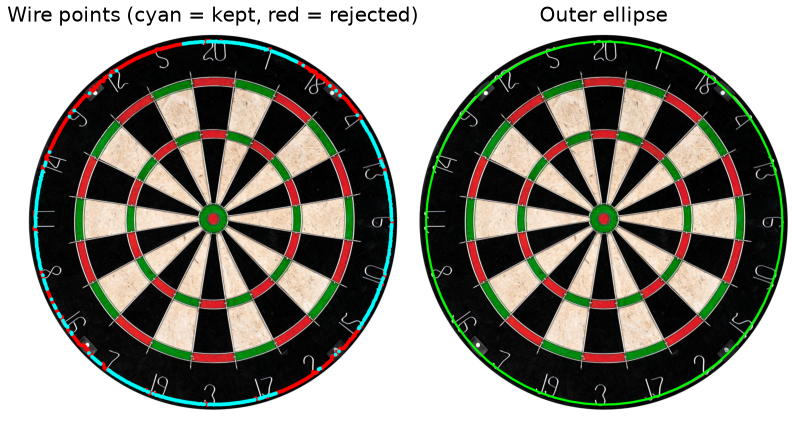

In [18]:
from src.calibration import find_centre, find_outer_ellipse
from src.geometry import crop_around

original = cv2.imread("..\\data\\dart_boards\\origin.png")
centre, edges, votes = find_centre(original)

gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

outer_ellipse, outer_points, outer_inliers = find_outer_ellipse(gray, centre)

print(f"{len(outer_inliers)} of {N_ANGLES} directions agree with the ellipse")
print("Outer ellipse: centre", np.round(outer_ellipse[0], 1), "axes", np.round(outer_ellipse[1], 1), "angle", round(outer_ellipse[2], 1))

half_size = int(0.56 * max(outer_ellipse[1]))
result = original.copy()
for x, y in outer_points:
    cv2.circle(result, (int(x), int(y)), 10, (255, 0, 0), -1)
for x, y in outer_inliers:
    cv2.circle(result, (int(x), int(y)), 10, (0, 255, 255), -1)
points_view = result

result = original.copy()
cv2.ellipse(result, outer_ellipse, (0, 255, 0), 10, cv2.LINE_AA)
ellipse_view = result

fig, axs = plt.subplots(1, 2, figsize=(11, 6))

axs[0].imshow(points_view, aspect="auto")
axs[0].set_title("Wire points (cyan = kept, red = rejected)", fontsize = 20)
axs[0].axis("off")
axs[1].imshow(ellipse_view, aspect="auto")
axs[1].set_title("Outer ellipse", fontsize = 20)
axs[1].axis("off")

plt.tight_layout()

if SAVE_FIGURE:
    save_path = Path(FIGURE_DIR) / "Implementation" / "Board Isolating" / "Outer_Ellipse_Fit.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    fig.savefig(save_path, dpi=500, bbox_inches="tight")

plt.show()

## **Inner Ellipse**

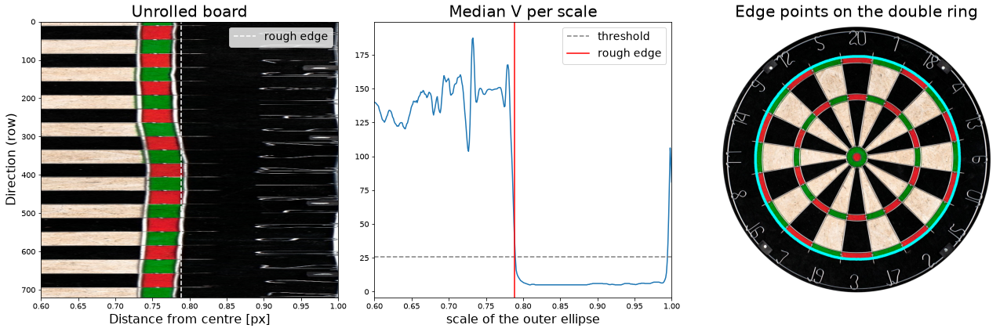

In [20]:
from src.calibration import find_centre, find_outer_ellipse, find_inner_edge
from src.geometry import crop_around

original = cv2.imread("..\\data\\dart_boards\\origin.png")
centre, edges, votes = find_centre(original)

gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

outer_ellipse, outer_points, outer_inliers = find_outer_ellipse(gray, centre)

inner_points, details = find_inner_edge(original, outer_ellipse, centre)

fig, axs = plt.subplots(1, 3, figsize=(18, 6))

axs[0].imshow(details["unrolled"], cmap="gray", aspect="auto", extent=[0.3, 1, N_ANGLES, 0])
axs[0].axvline(details["rough_edge"], color="w", linestyle="--", label = "rough edge")
axs[0].set_xlim(0.6, 1)
axs[0].set_title("Unrolled board", fontsize= 20)
axs[0].set_xlabel("Distance from centre [px]", fontsize= 16)
axs[0].set_ylabel("Direction (row)", fontsize= 16)
axs[0].legend(fontsize=14)

axs[1].plot(details["scales"], details["brightness"])
axs[1].axhline(details["threshold"], color="gray", linestyle="--", label="threshold")
axs[1].axvline(details["rough_edge"], color="r", label="rough edge")
axs[1].set_xlim(0.6, 1)
axs[1].set_title("Median V per scale", fontsize= 20)
axs[1].set_xlabel("scale of the outer ellipse", fontsize= 16)
axs[1].legend(fontsize=14)

result = original.copy()
for x, y in inner_points:
    cv2.circle(result, (int(x), int(y)), 10, (0, 255, 255), -1)

axs[2].imshow(result)
axs[2].set_title("Edge points on the double ring", fontsize= 20)
axs[2].axis("off")
plt.tight_layout()

if SAVE_FIGURE:
    save_path = Path(FIGURE_DIR) / "Implementation" / "Board Isolating" / "Inner_Ellipse_Fit.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    fig.savefig(save_path, dpi=500, bbox_inches="tight")
            
plt.show()

## **Fit Inner Ellipse**

586 of 720 directions agree with the ellipse
Inner ellipse is 0.7877 x the outer ellipse


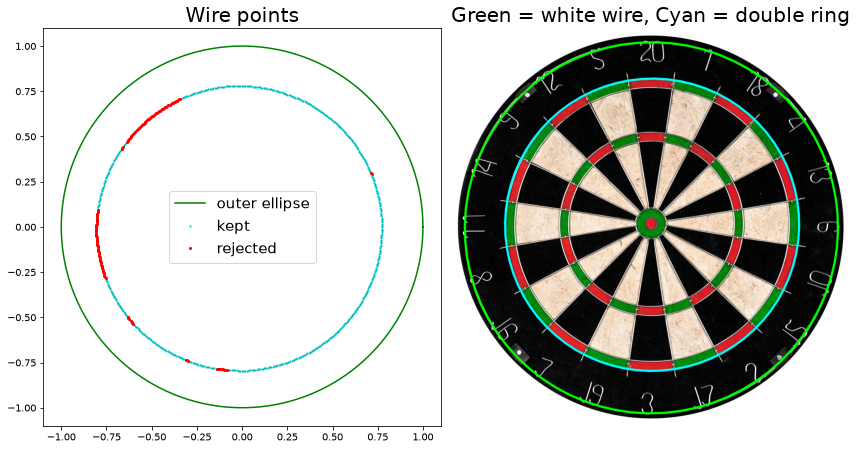

In [21]:
from src.calibration import find_centre, find_outer_ellipse, find_inner_edge
from src.geometry import fit_same_shape_ellipse, to_unit_circle, fit_circle
from src.geometry import crop_around

original = cv2.imread("..\\data\\dart_boards\\origin.png")
centre, edges, votes = find_centre(original)

gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

outer_ellipse, outer_points, outer_inliers = find_outer_ellipse(gray, centre)

inner_points, details = find_inner_edge(original, outer_ellipse, centre)

inner_ellipse, ratio, inner_inliers = fit_same_shape_ellipse(inner_points, outer_ellipse)

print(f"{inner_inliers.sum()} of {N_ANGLES} directions agree with the ellipse")
print(f"Inner ellipse is {ratio:.4f} x the outer ellipse")

u, v = to_unit_circle(inner_points, outer_ellipse)
a, b, radius = fit_circle(u[inner_inliers], v[inner_inliers])
t = np.linspace(0, 2 * np.pi, 360)

fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].plot(np.cos(t), np.sin(t), color="g", label="outer ellipse")
# axs[0].plot(a + radius * np.cos(t), b + radius * np.sin(t), color="k", label="fitted circle")
axs[0].plot(u[inner_inliers], v[inner_inliers], "c.", markersize=2, label="kept")
axs[0].plot(u[~inner_inliers], v[~inner_inliers], "r.", markersize=4, label="rejected")
axs[0].set_aspect("equal")
axs[0].set_title("Wire points", fontsize= 20)
axs[0].legend(loc="center", fontsize=15)

result = original.copy()
cv2.ellipse(result, outer_ellipse, (0, 255, 0), 10, cv2.LINE_AA)
cv2.ellipse(result, inner_ellipse, (0, 255, 255), 10, cv2.LINE_AA)
axs[1].imshow(result)
axs[1].set_title("Green = white wire, Cyan = double ring", fontsize= 20)
axs[1].axis("off")
plt.tight_layout()

if SAVE_FIGURE:
    save_path = Path(FIGURE_DIR) / "Implementation" / "Board Isolating" / "Inner_Ellipse.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    fig.savefig(save_path, dpi=500, bbox_inches="tight")
            
plt.show()

## **Results**

In [24]:
from src.calibration import calibrate_from_video, median_frame
from src.visualization import draw_board

boards = {}

for video in board_videos:
    image, _ = median_frame(video, amount=10)
    boards[video.stem] = calibrate_from_video(image)

print(f"{'video':32s} {'outer agree':>12s} {'inner agree':>12s} {'inner/outer':>12s} {'axis ratio':>11s} {'seconds':>8s}")
for name, b in boards.items():
    axes = b["outer"][1]
    print(f"{name:32s} {b['outer_agreement']:12.0%} {b['inner_agreement']:12.0%} {b['ratio']:12.4f} "
          f"{min(axes) / max(axes):11.3f} {b['seconds']:8.1f}")

video                             outer agree  inner agree  inner/outer  axis ratio  seconds
black_background_LightChange              91%          98%       0.7866       0.977      1.5
black_background_noHuman                  91%          98%       0.7870       0.981      1.6
black_background_yesHuman                 91%          98%       0.7871       0.981      1.5
white_background_LightChange              78%          94%       0.7854       0.938      0.8
white_background_noHuman                  82%          97%       0.7859       0.938      0.9
white_background_yesHuman                 83%          97%       0.7860       0.937      2.0
wood_background_Angle                     89%          96%       0.7912       0.862      8.0
wood_background_LightChange               90%          96%       0.7901       0.958     14.0
wood_background_noHuman                   92%          97%       0.7924       0.959      7.7
wood_background_yesHuman                  91%          97%       0.790

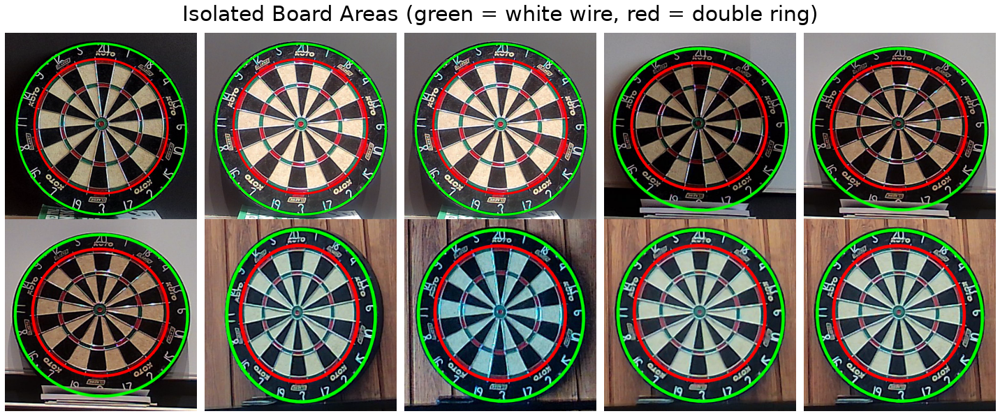

In [ ]:
fig, axs = plt.subplots(2, 5, figsize=(20, 8.4))

for ax, (name, b) in zip(axs.ravel(), boards.items()):
    half_size = int(0.56 * max(b["outer"][1]))
    output = crop_around(draw_board(b["image"], b, thickness = 3), b["outer"][0], half_size)
    ax.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    # ax.set_title(name, fontsize=10)
    ax.axis("off")

plt.suptitle("Isolated Board Areas (green = white wire, red = double ring)", fontsize= 30)
plt.tight_layout()

if SAVE_FIGURE:
    save_path = Path(FIGURE_DIR) / "Implementation" / "Board Isolating" / "board_detection_all_videos.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    plt.savefig(save_path, dpi=500, bbox_inches="tight")

plt.show()

# **Board Fields**

In [ ]:
from src.calibration import calibrate_from_video
from src.geometry import unroll_board
from src.visualization import draw_board


In [ ]:
boards = {video.stem: calibrate_from_video(video) for video in board_videos}


In [ ]:
example_name = "wood_background_noHuman"
board = boards[example_name]
image = board["image"]

## **Unroll Board**

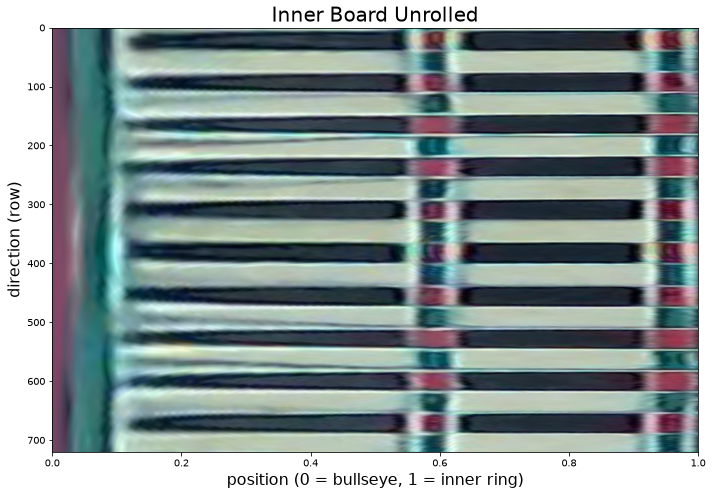

In [ ]:
unrolled, map_x, map_y = unroll_board(image, board["inner"], board["bullseye"], np.linspace(0, 1, N_COLUMNS), radians = True)

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(unrolled, cv2.COLOR_BGR2RGB), aspect="auto", extent=[0, 1, N_ROWS, 0])
plt.xlabel("position (0 = bullseye, 1 = inner ring)", fontsize = 16)
plt.ylabel("direction (row)", fontsize = 16)
plt.title("Inner Board Unrolled", fontsize = 20)
plt.tight_layout()

if SAVE_FIGURE:
    save_path = Path(FIGURE_DIR) / "Implementation" / "Board Fields" / "Unroll_Inner.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    plt.savefig(save_path, dpi=500, bbox_inches="tight")

plt.show()

## **Find Horizontal Lines (Sectors)**

Rows between the boundaries: smallest 33 largest 38


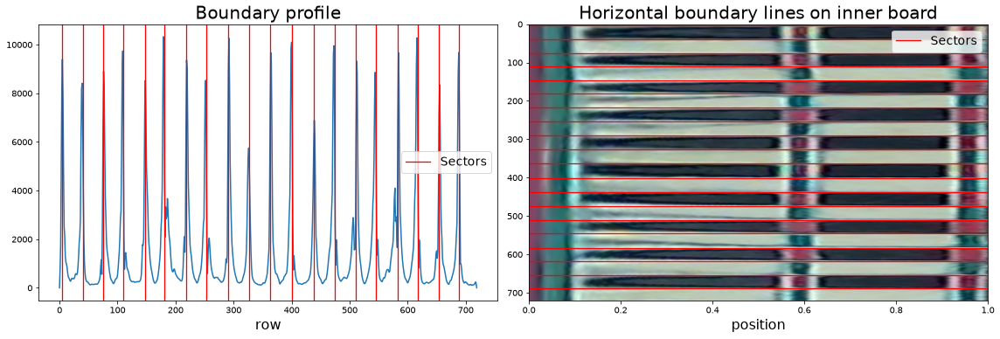

In [ ]:
from src.field_detection import boundary_profile, equalise_sectors, find_sector_rows

gray = cv2.cvtColor(unrolled, cv2.COLOR_BGR2GRAY).astype(np.float32)
profile = boundary_profile(gray)
sector_rows = equalise_sectors(find_sector_rows(profile))

print("Rows between the boundaries: smallest", np.diff(sector_rows).min(), "largest", np.diff(sector_rows).max())

fig, axs = plt.subplots(1, 2, figsize=(16, 5.5))

axs[0].plot(profile)
once = False
for row in sector_rows:
    if not once:
        axs[0].axvline(row, color="r", linewidth=1.3, label = "Sectors")
        once = True
    else:
        axs[0].axvline(row, color="r", linewidth=1.3)
axs[0].set_xlabel("row", fontsize = 16)
axs[0].legend(fontsize=14)
axs[0].set_title("Boundary profile", fontsize = 20)

axs[1].imshow(cv2.cvtColor(unrolled, cv2.COLOR_BGR2RGB), aspect="auto", extent=[0, 1, N_ROWS, 0])
for row in sector_rows:
    if once:
        axs[1].axhline(row, color="red", linewidth=1.3, label = "Sectors")
        once = False
    else:
        axs[1].axhline(row, color="red", linewidth=1.3)
axs[1].set_xlabel("position", fontsize = 16)
axs[1].set_title("Horizontal boundary lines on inner board", fontsize = 20)
axs[1].legend(fontsize=14)

plt.tight_layout()

if SAVE_FIGURE:
    save_path = Path(FIGURE_DIR) / "Implementation" / "Board Fields" / "Unroll_Horizontal_Boundaries.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    fig.savefig(save_path, dpi=500, bbox_inches="tight")

plt.show()

## **Find Vertical Lines (Rings)**

{'bull': 0.039, 'outer_bull': 0.103, 'treble_inner': 0.558, 'treble_outer': 0.62, 'double_inner': 0.927, 'double_outer': 0.987}


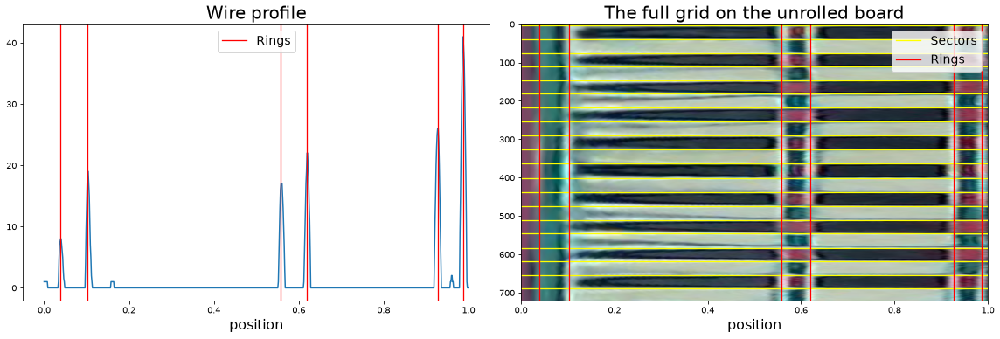

In [ ]:
from src.field_detection import find_rings

rings, wire_profile = find_rings(gray)
print({name: round(value, 3) for name, value in rings.items()})

positions = np.linspace(0, 1, N_COLUMNS)
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5))

axs[0].plot(positions, wire_profile)
once = False
for value in rings.values():
    if not once:
        axs[0].axvline(value, color="r", linewidth=1.3, label = "Rings")
        once = True
    else:
        axs[0].axvline(value, color="r", linewidth=1.3)
axs[0].set_xlabel("position", fontsize=16)
axs[0].set_title("Wire profile", fontsize = 20)
axs[0].legend(fontsize=14)

axs[1].imshow(cv2.cvtColor(unrolled, cv2.COLOR_BGR2RGB), aspect="auto", extent=[0, 1, N_ROWS, 0])
for row in sector_rows:
    if once:
        axs[1].axhline(row, color="yellow", linewidth=1.3, label = "Sectors")
        once = False
    else:
        axs[1].axhline(row, color="yellow", linewidth=1.3)

for value in rings.values():
    if not once:
        axs[1].axvline(value, color="red", linewidth=1.3, label = "Rings")
        once = True
    else:
        axs[1].axvline(value, color="red", linewidth=1.3)
axs[1].set_xlabel("position", fontsize=16)
axs[1].set_title("The full grid on the unrolled board", fontsize = 20)
axs[1].legend(fontsize=14)
plt.tight_layout()

if SAVE_FIGURE:
    save_path = Path(FIGURE_DIR) / "Implementation" / "Board Fields" / "Unroll_Vertical_Boundaries.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    fig.savefig(save_path, dpi=500, bbox_inches="tight")

plt.show()

## **Mark Fields**

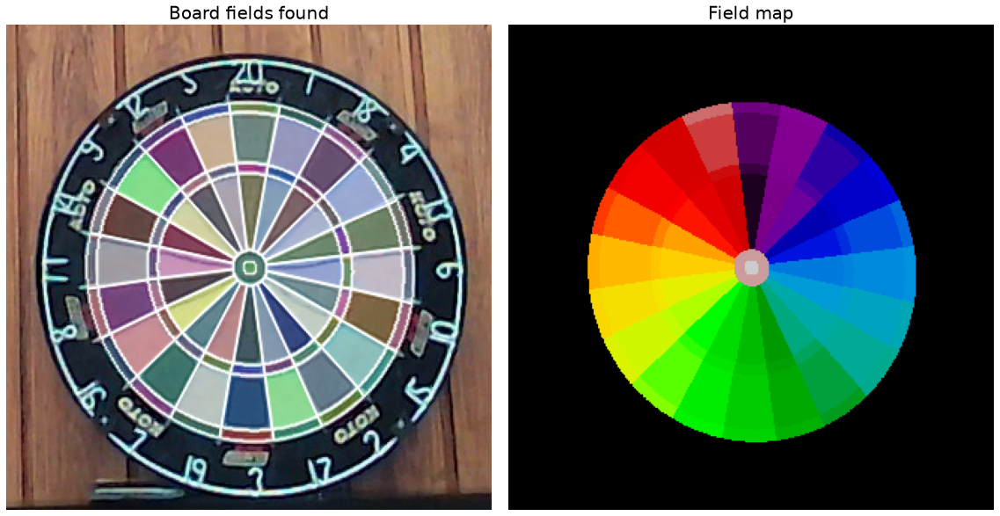

In [ ]:
from src.field_detection import  name_sectors
from src.scoring import build_fields, build_field_map
from src.visualization import draw_fields

sectors, brightness = name_sectors(gray, sector_rows)
fields = build_fields(sectors, rings, map_x, map_y)
field_map = build_field_map(fields, image.shape)

fig, axs = plt.subplots(1, 2, figsize=(16, 8))
marked = draw_fields(image, fields, field_map)
axs[0].imshow(cv2.cvtColor(crop_around(marked, board["bullseye"], half_size), cv2.COLOR_BGR2RGB))
axs[0].set_title("Board fields found", fontsize = 20)
axs[0].axis("off")

axs[1].imshow(crop_around(field_map.astype(np.float32) + 1, board["bullseye"], half_size), cmap="nipy_spectral")
axs[1].set_title("Field map", fontsize = 20)
axs[1].axis("off")
plt.tight_layout()

if SAVE_FIGURE:
    save_path = Path(FIGURE_DIR) / "Implementation" / "Board Fields" / "Field_mapping.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    plt.savefig(save_path, dpi=500, bbox_inches="tight")

plt.show()

## **Results**

In [ ]:
from src.field_detection import detect_fields
results = {name: detect_fields(b["image"], b) for name, b in boards.items()}

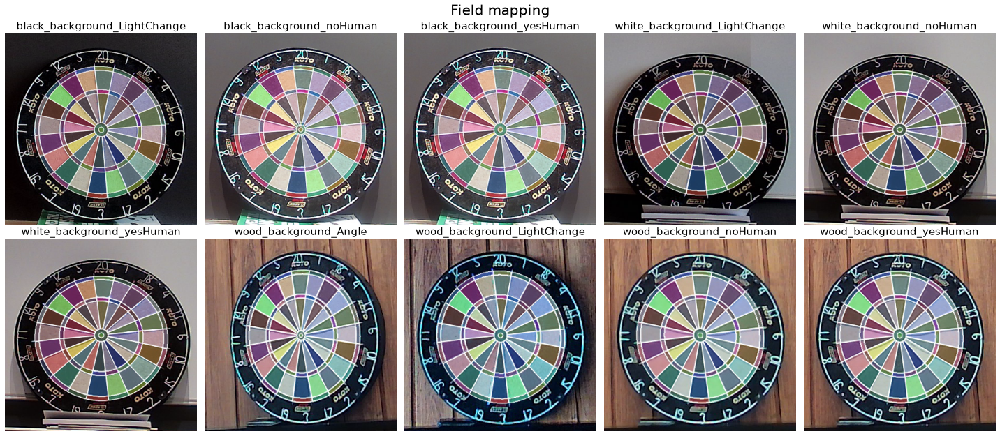

In [ ]:
fig, axs = plt.subplots(2, 5, figsize=(20, 9))

for ax, (name, r) in zip(axs.ravel(), results.items()):
    half_size = int(0.72 * max(boards[name]["inner"][1]))
    output = crop_around(draw_fields(r["image"], r["fields"], r["field_map"]), boards[name]["bullseye"], half_size)
    ax.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    ax.set_title(name, fontsize=15)
    ax.axis("off")

plt.suptitle("Field mapping", fontsize = 20)
plt.tight_layout()

if SAVE_FIGURE:
    save_path = Path(FIGURE_DIR) / "Implementation" / "Board Fields" / "Field_mapping_results.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    plt.savefig(save_path, dpi=500, bbox_inches="tight")

plt.show()

In [ ]:
from src.config import RING_GUESSES
print(f"{'video':32s} {'alternating':>12s} {'fields':>7s} {'top sector':>11s} {'smallest/largest gap [rows]':>28s}")

for name, r in results.items():
    # True if the brightness goes up and down at every step round the board
    dark = r["brightness"] < np.median(r["brightness"])
    alternating = np.all(dark != np.roll(dark, 1))

    fields_found = len(np.unique(r["field_map"][r["field_map"] >= 0]))
    gaps = np.diff(np.r_[r["sector_rows"], r["sector_rows"][0] + N_ROWS])

    print(f"{name:32s} {str(alternating):>12s} {fields_found:7d} {r['sectors'][0][0]:11d} {gaps.min():14d} / {gaps.max()}")

print("\nRing positions over all videos:")
for ring in RING_GUESSES:
    values = [r["rings"][ring] for r in results.values()]
    print(f"{ring:14s} mean {np.mean(values):.3f}   lowest {min(values):.3f}   highest {max(values):.3f}")

video                             alternating  fields  top sector  smallest/largest gap [rows]


black_background_LightChange             True      82          20             34 / 38
black_background_noHuman                 True      82          20             34 / 39
black_background_yesHuman                True      82          20             34 / 39
white_background_LightChange             True      82          20             32 / 40
white_background_noHuman                 True      82          20             34 / 39
white_background_yesHuman                True      82          20             33 / 39
wood_background_Angle                    True      82          20             33 / 40
wood_background_LightChange              True      82          20             33 / 39
wood_background_noHuman                  True      82          20             33 / 38
wood_background_yesHuman                 True      82          20             33 / 38

Ring positions over all videos:
bull           mean 0.037   lowest 0.029   highest 0.041
outer_bull     mean 0.096   lowest 0.070   highest

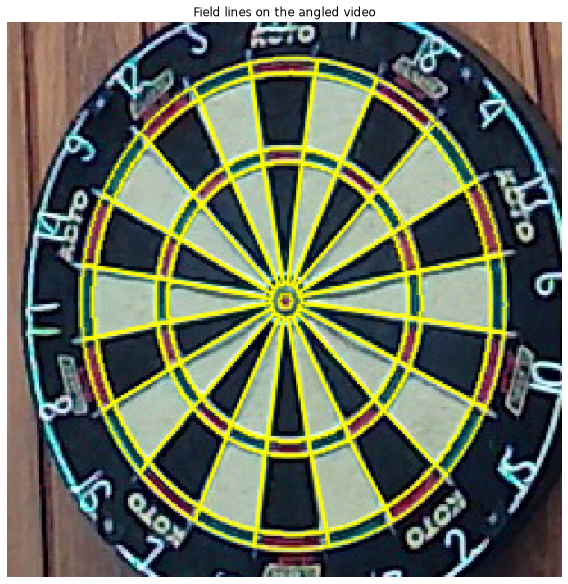

In [ ]:
name = "wood_background_Angle"
r = results[name]

lines = r["image"].copy()
for field in r["fields"]:
    cv2.polylines(lines, [field["outline"]], True, (0, 255, 255), 1, cv2.LINE_AA)

half_size = int(0.56 * max(boards[name]["inner"][1]))
zoomed = cv2.resize(crop_around(lines, boards[name]["bullseye"], half_size), None, fx=2.5, fy=2.5, interpolation=cv2.INTER_NEAREST)

plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(zoomed, cv2.COLOR_BGR2RGB))
plt.title("Field lines on the angled video")
plt.axis("off")
plt.show()

# **Dart Detection**

In [25]:
from src.Board import DartBoard
from src.dart_detection import calculate_difference

In [26]:
import cv2
import numpy as np
import pandas as pd

from src.Board import DartBoard

from src.scoring import field_at
from collections import deque

DISPLAY_WIDTH = 800
DISPLAY_HEIGHT = 500
def prepare_display(image):
    if image.dtype != np.uint8:
        image = cv2.normalize(
            image, None, 0, 255, cv2.NORM_MINMAX
        ).astype(np.uint8)

    if image.ndim == 2:
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

    return cv2.resize(image, (DISPLAY_WIDTH, DISPLAY_HEIGHT))
CAMERA_ON = False

MEAN_CHANGE_THRESHOLD = 1.5
PIXEL_CHANGE_THRESHOLD = 200

STABILITY_THRESHOLD = 2.0
STABLE_FRAMES_REQUIRED = 10
MIN_PERSISTENT_CHANGE = 0.35

AUTO_UPDATE_REFERENCE = True
COOLDOWN_FRAMES = 10
WARMUP_FRAMES = 10
BASELINE_FRAMES = 10


def main(video_path, show_video=True):
    board = DartBoard()

    reference_board = None
    previous_board = None
    measurements = []

    state = "WAITING"
    stable_frames = 0
    cooldown_frames = 0
    dart_count = 0
    throw_count = 0
    frame_count = 0
    total_points = 0

    baseline_history = deque(maxlen=BASELINE_FRAMES)
    baseline_before_impact = 0.0
    mask, isolated =  np.zeros((7, 7,3), dtype=np.uint8), np.zeros((7, 7,3), dtype=np.uint8)
    endpoint = None

    path = 1 if CAMERA_ON else str(video_path)
    cap = cv2.VideoCapture(path)

    if not cap.isOpened():
        cap.release()
        raise FileNotFoundError(f"Cannot open video: {path}")

    start_time = cv2.getTickCount() / cv2.getTickFrequency()

    print(
        f"Thresholds: impact > {MEAN_CHANGE_THRESHOLD}, "
        f"stability < {STABILITY_THRESHOLD}, "
        f"stable frames >= {STABLE_FRAMES_REQUIRED}, "
        f"persistent change > {MIN_PERSISTENT_CHANGE}"
    )

    try:
        while True:
            ret, frame = cap.read()

            if not ret:
                break

            board.update_frame(frame)

            if not board.calibrated:
                board.calibrate(frame)

            if not board.fields_detected:
                board.detect_scoring_fields()

            ROI_board, (x0, y0) = board.outer_drawn_fields(with_fields=False)
            frame_count += 1

            if frame_count <= WARMUP_FRAMES:
                reference_board = ROI_board.copy()
                previous_board = ROI_board.copy()
                continue

            if reference_board is None:
                reference_board = ROI_board.copy()

            if CAMERA_ON:
                timestamp = (
                    cv2.getTickCount() / cv2.getTickFrequency()
                    - start_time
                )
            else:
                timestamp = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000.0

            measurement = calculate_difference(
                reference_board,
                ROI_board,
                timestamp,
                mean_change_threshold=MEAN_CHANGE_THRESHOLD,
                pixel_threshold=PIXEL_CHANGE_THRESHOLD
            )

            mean_difference = measurement["mean_difference"]

            stability = 0.0

            if previous_board is not None:
                frame_difference = cv2.absdiff(
                    previous_board,
                    ROI_board
                )

                gray_frame_difference = cv2.cvtColor(
                    frame_difference,
                    cv2.COLOR_BGR2GRAY
                )

                stability = float(np.mean(gray_frame_difference))

            measurement["stability"] = round(stability, 3)
            measurement["dart_thrown"] = 0

            baseline = (
                float(np.median(baseline_history))
                if baseline_history
                else mean_difference
            )

            impact_change = mean_difference - baseline
            baseline_ready = len(baseline_history) >= BASELINE_FRAMES

            measurement["baseline"] = round(baseline, 3)
            measurement["impact_change"] = round(impact_change, 3)
            measurement["change_detected"] = (
                baseline_ready
                and impact_change > MEAN_CHANGE_THRESHOLD
            )

            if state == "WAITING":

                if not baseline_ready:
                    baseline_history.append(mean_difference)

                    if len(baseline_history) == BASELINE_FRAMES:
                        print(
                            f"[{timestamp:.2f}s] Baseline initialized: "
                            f"{np.median(baseline_history):.3f}"
                        )

                elif measurement["change_detected"]:
                    throw_count += 1
                    measurement["dart_thrown"] = 1

                    baseline_before_impact = baseline
                    state = "SETTLING"
                    stable_frames = 0

                    print(
                        f"\n[{timestamp:.2f}s] Throw {throw_count} detected"
                        f"\n  Mean difference: {mean_difference:.3f}"
                        f"\n  Baseline:        {baseline:.3f}"
                        f"\n  Impact change:   {impact_change:.3f}"
                        f"\n  Threshold:       {MEAN_CHANGE_THRESHOLD:.3f}"
                    )

                else:
                    baseline_history.append(mean_difference)

            elif state == "SETTLING":

                if stability < STABILITY_THRESHOLD:
                    stable_frames += 1
                else:
                    stable_frames = 0

                if stable_frames >= STABLE_FRAMES_REQUIRED:

                    persistent_change = (
                        mean_difference - baseline_before_impact
                    )

                    measurement["persistent_change"] = round(
                        persistent_change, 3
                    )

                    if persistent_change > MIN_PERSISTENT_CHANGE:
                        dart_count += 1
                        measurement["dart_landed"] = 1
                        result = "LANDED"
                    else:
                        measurement["dart_missed"] = 1
                        result = "MISSED / BOUNCED"

                    print(
                        f"[{timestamp:.2f}s] Throw {throw_count}: {result}"
                        f"\n  Mean difference:   {mean_difference:.3f}"
                        f"\n  Pre-impact base:   {baseline_before_impact:.3f}"
                        f"\n  Persistent change: {persistent_change:.3f}"
                        f"\n  Landing threshold: {MIN_PERSISTENT_CHANGE:.3f}"
                        f"\n  Stability:         {stability:.3f}"
                        f"\n  Stable frames:     {stable_frames}"
                        f"\n  Landed:            {dart_count}/{throw_count}\n"
                    )

                    if AUTO_UPDATE_REFERENCE:
                        # Place isoalte dart here
                        reference_board = ROI_board.copy()

                    baseline_history.clear()

                    state = "COOLDOWN"
                    cooldown_frames = 0

            elif state == "COOLDOWN":

                cooldown_frames += 1

                if cooldown_frames >= COOLDOWN_FRAMES:
                    if (
                        AUTO_UPDATE_REFERENCE
                        or not measurement["change_detected"]
                    ):
                        state = "WAITING"
                        cooldown_frames = 0

            measurement["state"] = state
            measurement["dart_count"] = dart_count
            measurement["throw_count"] = throw_count
            measurement["stable_frames"] = stable_frames

            measurements.append(measurement)
            previous_board = ROI_board.copy()

            if show_video:
                processed, (x0, y0) = board.outer_drawn_fields(with_fields=True)

                frame_display = cv2.resize(
                    frame, (DISPLAY_WIDTH, DISPLAY_HEIGHT)
                )

                processed_display = cv2.resize(
                    processed, (DISPLAY_WIDTH, DISPLAY_HEIGHT)
                )

                cv2.putText(
                    frame_display,
                    "Original Frame",
                    (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    1, (0, 255, 0), 2
                )

                cv2.putText(
                    processed_display,
                    f"Darts landed: {dart_count}/{throw_count}",
                    (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.8, (0, 255, 0), 2
                )

                cv2.putText(
                    processed_display,
                    f"State: {state}",
                    (20, 80),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7, (0, 255, 255), 2
                )

                cv2.putText(
                    processed_display,
                    f"Difference: {mean_difference:.2f}",
                    (20, 120),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7, (255, 255, 255), 2
                )

                cv2.putText(
                    processed_display,
                    f"Impact: {impact_change:.2f}",
                    (20, 160),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7, (255, 255, 255), 2
                )

                cv2.putText(
                    processed_display,
                    f"Stability: {stability:.2f}",
                    (20, 200),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7, (255, 255, 255), 2
                )

                
                combined = np.vstack((
                    np.hstack((
                        frame_display,
                        processed_display
                    )),
                    np.hstack((
                        prepare_display(ROI_board),
                        prepare_display(isolated)
                    ))
                ))

                cv2.imshow("Original | Processed", combined)

                if cv2.waitKey(5) & 0xFF == ord("q"):
                    break

    finally:
        cap.release()
        cv2.destroyAllWindows()

    print(
        f"\nFinal result: {dart_count} landed "
        f"out of {throw_count} detected throws.\n"
        f"Total amounts of points: {total_points}"

    )

    result = pd.DataFrame(measurements)
    result["video"] = str(video_path)
    return result

In [27]:
from pathlib import Path
import pandas as pd

VIDEO_FOLDER = Path(r"..\data\dart_videos")

video_paths = sorted(
    p for p in VIDEO_FOLDER.iterdir()
    if p.suffix.lower() in {".mp4"}
)

all_results = []

for i, video_path in enumerate(video_paths, 1):
    print(f"\n[{i}/{len(video_paths)}] Testing: {video_path.name}")

    try:
        result = main(video_path=video_path, show_video=False)
        result["video"] = video_path.stem
        all_results.append(result)

        print(
            f"Detected: {int(result['throw_count'].max())} throws, "
            f"{int(result['dart_count'].max())} landed"
        )

    except Exception as e:
        print(f"Failed: {video_path.name}: {e}")

all_data = pd.concat(all_results, ignore_index=True) if all_results else pd.DataFrame()


[1/10] Testing: dart_19_19point.mp4
Thresholds: impact > 1.5, stability < 2.0, stable frames >= 10, persistent change > 0.35
[0.64s] Baseline initialized: 2.103

[1.57s] Throw 1 detected
  Mean difference: 4.199
  Baseline:        2.274
  Impact change:   1.925
  Threshold:       1.500
[2.43s] Throw 1: LANDED
  Mean difference:   2.769
  Pre-impact base:   2.274
  Persistent change: 0.495
  Landing threshold: 0.350
  Stability:         1.769
  Stable frames:     10
  Landed:            1/1


Final result: 1 landed out of 1 detected throws.
Total amounts of points: 0
Detected: 1 throws, 1 landed

[2/10] Testing: dart_20_20point.mp4
Thresholds: impact > 1.5, stability < 2.0, stable frames >= 10, persistent change > 0.35
[0.62s] Baseline initialized: 2.074

[1.76s] Throw 1 detected
  Mean difference: 3.917
  Baseline:        2.285
  Impact change:   1.631
  Threshold:       1.500
[2.86s] Throw 1: LANDED
  Mean difference:   2.783
  Pre-impact base:   2.285
  Persistent change: 0.498
  La

OSError: [Errno 22] Invalid argument: '..\\reports\\figures\\Implementation\\Dart Recognition\\dart_rec_params.png'

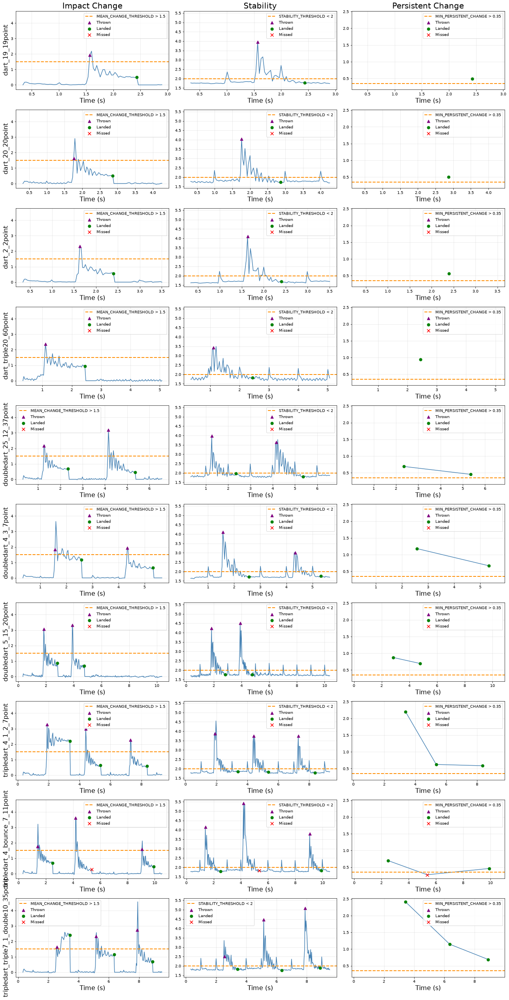

In [30]:
import matplotlib.pyplot as plt
import numpy as np

def plot_scenario_comparison(data, save_fig: bool = False):
    videos = data["video"].unique()

    metrics = [
        ("impact_change", MEAN_CHANGE_THRESHOLD,
         "MEAN_CHANGE_THRESHOLD", ">"),
        ("stability", STABILITY_THRESHOLD,
         "STABILITY_THRESHOLD", "<"),
        ("persistent_change", MIN_PERSISTENT_CHANGE,
         "MIN_PERSISTENT_CHANGE", ">")
    ]

    fig, axes = plt.subplots(
        len(videos), 3,
        figsize=(18, 3.5 * len(videos)),
        squeeze=False,
        sharex="row",
        sharey="col"
    )

    for i, video in enumerate(videos):
        df = data[data["video"] == video]

        for j, (column, threshold, name, operator) in enumerate(metrics):
            ax = axes[i, j]

            valid = df[column].notna()

            ax.plot(
                df.loc[valid, "time"],
                df.loc[valid, column],
                color="steelblue",
                linewidth=1.5
            )

            ax.axhline(
                threshold,
                color="darkorange",
                linestyle="--",
                linewidth=2,
                label=f"{name} {operator} {threshold:g}"
            )

            detected = df["dart_thrown"].eq(1) & valid
            landed = df["dart_landed"].eq(1) & valid
            missed = df["dart_missed"].eq(1) & valid

            ax.scatter(
                df.loc[detected, "time"],
                df.loc[detected, column],
                color="purple",
                marker="^",
                s=50,
                label="Thrown",
                zorder=5
            )

            ax.scatter(
                df.loc[landed, "time"],
                df.loc[landed, column],
                color="green",
                s=50,
                label="Landed",
                zorder=5
            )

            ax.scatter(
                df.loc[missed, "time"],
                df.loc[missed, column],
                color="red",
                marker="x",
                s=60,
                label="Missed",
                zorder=5
            )

            if i == 0:
                ax.set_title(column.replace("_", " ").title(), fontsize = 20)

            if j == 0:
                ax.set_ylabel(str(video), fontsize = 16)

            ax.set_xlabel("Time (s)", fontsize = 16)
            ax.grid(True, alpha=0.3)
            ax.legend(fontsize=10)

    plt.tight_layout()
    if save_fig:
        save_path = Path(FIGURE_DIR) / "Implementation" / "Dart Recognition" / "dart_rec_params.png"
        save_path.parent.mkdir(parents=True, exist_ok=True)

        plt.savefig(save_path, dpi=500, bbox_inches="tight")
    plt.show()
plot_scenario_comparison(all_data, SAVE_FIGURE)